In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt # Para editar leyendas de las gráficas

/home/nesper94/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


![Niceforonia tempestuosa](https://imgs.mongabay.com/wp-content/uploads/sites/25/2026/08/28214418/oo_1742761-1200x800.jpg)

La rana *Niceforonia tempestuosa*, tiene un tamaño promedio de $ 24 \pm 1 \text{ mm} $. Cree un conjunto de 40.000 valores con distribución normal que representarán la **población** de ranas:

In [2]:
población = np.random.normal(loc=24, scale=1, size=40000)

Grafiquemos el histograma de estos valores:

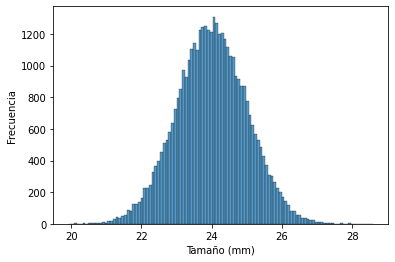

In [3]:
sns.histplot(población)
plt.xlabel("Tamaño (mm)") # Editar título del eje X
plt.ylabel("Frecuencia") # Editar título del eje Y
plt.show() # Generar la gráfica

¿Cuáles son los valores máximos y mínimos de esta población?

In [4]:
np.min(población)

19.92845747696814

In [5]:
np.max(población)

28.594962781619326

Tomar una muestra de esta población:

In [6]:
muestra = np.random.choice(población, size=10)
muestra

array([23.62726212, 24.2129331 , 22.21074508, 23.75572502, 24.93906678,
       23.47146896, 23.06497354, 25.07500642, 23.3897556 , 24.44266067])

Calcular media y desviación estándar de la muestra:

In [7]:
np.mean(muestra)

23.818959729335916

In [8]:
np.std(muestra)

0.8292812021225006

## Ejercicio

Cree una función llamada `generar_medias` que tome un número $ m $ de muestras de tamaño $ n $ de la población anterior y que entregue como resultado una lista con las medias muestrales de las $ m $ muestras.

In [13]:
def generar_medias(m, n):
    medias = []
    
    for i in range(m):
        muestra = np.random.choice(población, size=n)
        promedio = np.mean(muestra)
        medias.append(promedio)
    
    return medias

Use la función anterior para generar 9000 medias de muestras de tamaño $ n = 10 $. Llame a esta lista `medias_n10`.

In [14]:
medias_n10 = generar_medias(9000, 10)

Grafique el histograma de estos valores usando `seaborn`.

<Axes: ylabel='Count'>

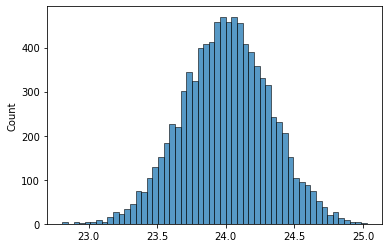

In [16]:
sns.histplot(medias_n10)

Calcule la desviación estándar de estos valores.

In [17]:
np.std(medias_n10)

0.31786231906331885

Repita el procedimiento anterior pero ahora con 9000 muestras de tamaño $ n = 40 $. Llame a la variable `medias_n40`:

In [18]:
medias_n40 = generar_medias(9000, 40)

Grafiquemos juntos ambos histogramas con el siguiente código:

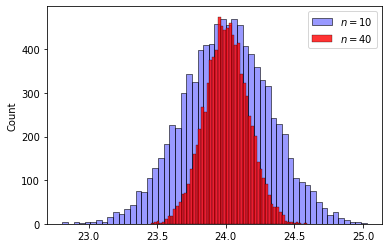

In [21]:
sns.histplot(medias_n10,
             color="blue",
             alpha=0.4,
             label="$ n = 10 $")

sns.histplot(medias_n40,
             color="red",
             alpha=0.8,
             label="$ n = 40 $")

plt.legend()
plt.show()

¿Qué cambio se puede observar en el histograma y en la desviación estándar?

# Error Estándar de la Media

El **error estándar** es la desviación estándar de la distribución muestral de un estadístico muestral, por ejemplo la media. Es decir, es la desviación estándar que tienen las medias muestrales tomadas de una población y su ecuación es:

## Valor exacto

$$ \sigma_{\bar{x}} = \dfrac{\sigma}{\sqrt{n}}, $$

donde $ \sigma $ es la desviación estándar **poblacional**, y $ n $ el tamaño de la muestra.

## Estimación

Como normalmente desconocemos $ \sigma $, se puede estimar el error estándar así:

$$ \sigma_{\bar{x}} \approx \dfrac{s}{\sqrt{n}}, $$

donde $ s $ es la desviación estándar **muestral**.

## Ejercicio

Calcule el error estándar de la media para muestras de tamaño 10 tomadas de la población de ranas:

In [22]:
sigma = np.std(población)
sigma

1.0002059707778415

In [24]:
# Muestras de tamaño 10
sigma/np.sqrt(10)

0.31629289969577945

¿Coincide este valor con el valor obtenido anteriormente para la desviación estándar de las 9000 medias provenientes de muestras de tamaño 10?

## Efecto del tamaño de la muestra ($ n $)

Ahora generemos 10000 medias a partir de muestras de tamaño $ n = 160 $. Calcule tanto el error estándar teórico como la desviación estándar de estos valores.

In [25]:
# Error estándar teórico
sigma/np.sqrt(160)

0.07907322492394486

In [26]:
medias_n160 = generar_medias(10000, 160)
np.std(medias_n160)

0.0799765090904227

¿Cómo es este valor con respecto a los obtenidos a partir de muestras de tamaño 10 y 40?